---
# **5. POBLACIÓN**

**Objetivo:** calcular cuánta población vulnerable al calor (niños de 0 a 4 años y personas mayores de 75) vive en cada barrio de Barcelona.

**Entradas:**
- En **`data/raw`**: `2026_pad_mdba_sexe_edat-q.csv`.
- En **`data/processed`**: `barrios_base.csv` (cuaderno 1).

**Fuente y año:** Open Data BCN (Ajuntament de Barcelona), Padró Municipal d'Habitants. Población a 1 de enero de 2026, por sexo y grupos de edad de cinco años.

**Salida** (en `data/processed`): `poblacion_por_barrio.csv`, una fila por barrio con `codi_barri` y las variables de población.

**Limitaciones:**
- Es la población **empadronada**: no incluye turistas ni a quien vive en un barrio sin estar empadronado allí.
- El archivo viene por áreas estadísticas básicas (AEB). Una AEB es una división estadística más pequeña que el barrio: cada barrio tiene entre 1 y 10, y 233 en toda la ciudad. **Las sumamos por barrio**.
- Los grupos de menos de 5 personas no se publican (aparecen como `..`). Los tratamos como 0, con un efecto muy pequeño.
- La edad es solo una parte de la vulnerabilidad: no tenemos datos de ingresos, salud o tipo de vivienda.
---

## Metodología previa: de dónde salen los datos

### A. ¿De dónde proceden?
Los datos vienen del **Padró Municipal d'Habitants**, el registro del Ayuntamiento con las personas empadronadas en la ciudad. Se publican en el portal **Open Data BCN**, en el conjunto de datos `pad_mdba_sexe_edat-q` (población por sexo y edad quinquenal), con un archivo por año. Usamos el de **2026** (población a 1 de enero de 2026), descargado en formato CSV.

### B. ¿Por qué estos dos grupos de edad?
Los niños pequeños y las personas mayores regulan peor la temperatura del cuerpo, y son los grupos más vulnerables a los episodios de calor intenso. En el proyecto usamos dos grupos:
- **0 a 4 años** (primer grupo de edad del archivo).
- **75 años o más** (la suma de los grupos de 75-79, 80-84, 85-89, 90-94, 95-99 y 100 y más).

### C. ¿Cómo está organizado el archivo?
Cada fila es **el número de personas de un sexo y un grupo de edad, en un área estadística básica (AEB)**:

| Columna | Qué contiene |
|---|---|
| `Data_Referencia` | Fecha del padrón |
| `Codi_Districte`, `Nom_Districte` | Distrito |
| `Codi_Barri`, `Nom_Barri` | Barrio |
| `AEB` | Área estadística básica dentro del barrio |
| `Valor` | Número de personas |
| `EDAT_Q` | Grupo de edad de cinco años (de 0 a 20) |
| `SEXE` | Sexo (dos valores) |

In [68]:
from google.colab import drive
drive.mount('/content/drive')

CARPETA = '/content/drive/MyDrive/proyectofinal_ITAcademy/'
RAW = CARPETA + 'data/raw/'                           # Ruta limpia a la carpeta de datos originales
PROCESSED = CARPETA + 'data/processed/'              # Ruta limpia a la carpeta de procesados

import os
os.makedirs(PROCESSED, exist_ok=True)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


Cargamos las librerías: **pandas** trabaja con tablas, **geopandas** es pandas con mapas y **matplotlib** dibuja gráficos.

In [69]:
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt

pd.set_option('display.max_columns', None)    # que pandas enseñe todas las columnas

## 1. Cargar los datos

In [70]:
poblacion = pd.read_csv(RAW + '2026_pad_mdba_sexe_edat-q.csv', encoding='utf-8-sig')

print('Filas y columnas:', poblacion.shape)

Filas y columnas: (9653, 9)


## 2. Inspección de los datos

### 2.1 Primeras filas y tipos de datos

In [71]:
display(poblacion.head())
print()
poblacion.info()

,Data_Referencia,Codi_Districte,Nom_Districte,Codi_Barri,Nom_Barri,AEB,Valor,EDAT_Q,SEXE
0,2026-01-01,1,Ciutat Vella,1,el Raval,1,42,0,1
1,2026-01-01,1,Ciutat Vella,1,el Raval,1,55,0,2
2,2026-01-01,1,Ciutat Vella,1,el Raval,1,51,1,1
3,2026-01-01,1,Ciutat Vella,1,el Raval,1,49,1,2
4,2026-01-01,1,Ciutat Vella,1,el Raval,1,61,2,1



<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9653 entries, 0 to 9652
Data columns (total 9 columns):
 #   Column           Non-Null Count  Dtype 
---  ------           --------------  ----- 
 0   Data_Referencia  9653 non-null   object
 1   Codi_Districte   9653 non-null   int64 
 2   Nom_Districte    9653 non-null   object
 3   Codi_Barri       9653 non-null   int64 
 4   Nom_Barri        9653 non-null   object
 5   AEB              9653 non-null   int64 
 6   Valor            9653 non-null   object
 7   EDAT_Q           9653 non-null   int64 
 8   SEXE             9653 non-null   int64 
dtypes: int64(5), object(4)
memory usage: 678.9+ KB


**Qué mirar:** cada fila es el número de personas (`Valor`) de un sexo (`SEXE`) y un grupo de edad (`EDAT_Q`) en una AEB. La columna `Valor` aparece como **texto** (`str`) en lugar de número.

### 2.2 ¿Qué columnas aportan información?

In [72]:
n_valores = poblacion.nunique()
print('Columnas con un solo valor (no aportan nada):', n_valores[n_valores == 1].index.tolist())
print()
print('Barrios:', poblacion['Codi_Barri'].nunique(), '| Distritos:', poblacion['Codi_Districte'].nunique())
print('Áreas estadísticas básicas (AEB):', poblacion[['Codi_Barri', 'AEB']].drop_duplicates().shape[0])
print('Códigos de barrio del 1 al 73 completos:', sorted(poblacion['Codi_Barri'].unique()) == list(range(1, 74)))

Columnas con un solo valor (no aportan nada): ['Data_Referencia']

Barrios: 73 | Distritos: 10
Áreas estadísticas básicas (AEB): 233
Códigos de barrio del 1 al 73 completos: True


**Qué mirar:** `Data_Referencia` solo tiene un valor (1 de enero de 2026), así que no la necesitamos. Hay 73 barrios, 10 distritos y 233 AEB (que habrá que sumar por barrio).

### 2.3 Valores vacíos y duplicados

In [73]:
print('Valores vacíos:', int(poblacion.isna().sum().sum()))
print('Filas repetidas (mismo barrio, AEB, edad y sexo):', poblacion.duplicated(subset=['Codi_Barri', 'AEB', 'EDAT_Q', 'SEXE']).sum())

Valores vacíos: 0
Filas repetidas (mismo barrio, AEB, edad y sexo): 0


**Qué mirar:** no hay vacíos ni duplicados. Pero hemos visto que `Valor` es texto, por lo que los valores faltantes pueden venir escritos de otra forma y que los datos no estén completos.

### 2.4 La columna `Valor`: ¿por qué es texto?

In [74]:
valor_num = pd.to_numeric(poblacion['Valor'], errors='coerce')     # lo que no es un número pasa a NaN
raros = poblacion[valor_num.isna()]

print('Filas donde Valor no es un número:', len(raros))
print('Qué contienen:', raros['Valor'].unique().tolist())
print('Valor numérico más pequeño:', int(valor_num.min()))
print()
print('Grupos de edad (EDAT_Q) donde aparecen:')
print(raros['EDAT_Q'].value_counts().sort_index())

filas_por_aeb = poblacion.groupby(['Codi_Barri', 'AEB']).size()
print()
print('AEB con menos de 42 filas (21 grupos de edad x 2 sexos):', int((filas_por_aeb < 42).sum()))

Filas donde Valor no es un número: 351
Qué contienen: ['..']
Valor numérico más pequeño: 5

Grupos de edad (EDAT_Q) donde aparecen:
EDAT_Q
17      1
18     13
19     91
20    246
Name: count, dtype: int64

AEB con menos de 42 filas (21 grupos de edad x 2 sexos): 113


**Qué mirar:**
- Hay **351 filas con `..`** en lugar de un número, y por eso la columna es texto.
- El valor numérico más pequeño del archivo es **5**: no hay ningún 1, 2, 3 ni 4. Parece que los grupos de **menos de 5 personas** no se publican y se marcan con `..`.
- Todos los `..` están en los grupos de edad **17 a 20** (los más mayores), donde hay pocas personas por AEB.
- Tampoco hay ningún 0: cuando en una AEB no hay nadie de un grupo, simplemente no hay fila (por eso 113 AEB tienen menos de 42).

### 2.5 Grupos de edad (`EDAT_Q`)
`EDAT_Q` va de 0 a 20: son 21 grupos de cinco años. Comprobamos a qué edad corresponde cada uno.

```
0 = 0-4 años, 1 = 5-9, 2 = 10-14 ... 15 = 75-79, 16 = 80-84, 17 = 85-89, 18 = 90-94, 19 = 95-99, 20 = 100 y más
```

In [75]:
etiquetas = {i: f'{5 * i}-{5 * i + 4}' for i in range(20)}
etiquetas[20] = '100 y más'

total_por_edad = valor_num.groupby(poblacion['EDAT_Q']).sum().astype(int)
edades = pd.DataFrame({'grupo_edad': [etiquetas[i] for i in total_por_edad.index],
                       'personas': total_por_edad.values}, index=total_por_edad.index)
display(edades)

,grupo_edad,personas
EDAT_Q,,
0,0-4,54438
1,5-9,61941
2,10-14,70944
3,15-19,77412
4,20-24,96207
5,25-29,131794
6,30-34,148776
7,35-39,135802
8,40-44,124956


**Qué mirar:** la correspondencia (0 = 0-4 años, 15 = 75-79, 20 = 100 y más) se deduce de los 21 grupos que aparecen en el archivo y es coherente con los datos: el grupo 0 tiene unas 54.438 personas, el 15 unas 71.640 y el 20 solo 703, como cabe esperar de las personas de 100 años o más.

## 3. Limpieza

### 3.1 Nos quedamos solo con lo que necesitamos y ponemos nombres claros

In [76]:
pob = poblacion[['Codi_Barri', 'AEB', 'EDAT_Q', 'SEXE', 'Valor']].copy()
pob = pob.rename(columns={
    'Codi_Barri': 'codi_barri',
    'AEB': 'aeb',
    'EDAT_Q': 'edat_q',
    'SEXE': 'sexe',
    'Valor': 'personas'})
display(pob.head(3))

,codi_barri,aeb,edat_q,sexe,personas
0,1,1,0,1,42
1,1,1,0,2,55
2,1,1,1,1,51


### 3.2 Los `..` pasan a ser 0
Convertimos `personas` a número. Los `..` (grupos de menos de 5 personas) los ponemos a 0. No sabemos cuántas personas hay exactamente (entre 1 y 4), así que esta opción **subestima un poco** la población. Calculamos cuánto como máximo.

In [77]:
pob['personas'] = pd.to_numeric(pob['personas'], errors='coerce')
n_dudosos = int(pob['personas'].isna().sum())
pob['personas'] = pob['personas'].fillna(0).astype(int)

mayores_75 = pob.loc[pob['edat_q'] >= 15, 'personas'].sum()
print('Filas con ".." pasadas a 0:', n_dudosos)
print('Como mucho faltan', n_dudosos * 4, 'personas, un', round(n_dudosos * 4 / mayores_75 * 100, 1), '% de los mayores de 75')

Filas con ".." pasadas a 0: 351
Como mucho faltan 1404 personas, un 0.7 % de los mayores de 75


**Qué mirar:** como mucho faltan unas 1.400 personas (351 filas x 4), el **0,7 %** de los mayores de 75. Es un error pequeño, y lo dejaremos escrito como limitación.

### 3.3 Marcamos los dos grupos de población vulnerable
- **0-4:** niños de 0 a 4 años (`edat_q` = 0).
- **75+:** personas de 75 años o más (`edat_q` de 15 a 20).
- **resto:** todas las demás edades.

In [78]:
pob['grupo'] = 'resto'
pob.loc[pob['edat_q'] == 0, 'grupo'] = '0_4'
pob.loc[pob['edat_q'] >= 15, 'grupo'] = '75+'

display(pob.groupby('grupo')['personas'].sum().to_frame('personas'))

,personas
grupo,
0_4,54438
75+,195222
resto,1479547


## 4. Variables por barrio

### 4.1 Sumamos las AEB de cada barrio
Con `pivot_table` sumamos las personas de todas las AEB y los dos sexos: una fila por barrio y una columna por grupo.

In [79]:
por_grupo = pob.pivot_table(index='codi_barri', columns='grupo', values='personas', aggfunc='sum', fill_value=0)
por_grupo = por_grupo.rename(columns={'0_4': 'pob_0_4', '75+': 'pob_75_mas', 'resto': 'pob_resto'})
por_grupo['pob_total'] = por_grupo.sum(axis=1)             # población total del barrio
por_grupo.columns.name = None                              # quitamos el nombre 'grupo' del encabezado
por_grupo = por_grupo.reset_index()

display(por_grupo.head())

,codi_barri,pob_0_4,pob_75_mas,pob_resto,pob_total
0,1,2054,2365,46406,50825
1,2,555,983,25757,27295
2,3,325,1248,13077,14650
3,4,519,1548,20906,22973
4,5,1017,3855,32799,37671


### 4.2 Unimos con los barrios y calculamos las variables finales
Traemos el nombre y la superficie de cada barrio (de `barrios_base.csv`) y calculamos, para la población vulnerable, **tres tipos de medidas**, porque responden a preguntas distintas:

- **Número de personas** (`pob_...`): *¿a cuánta gente afecta?*
- **Porcentaje** (`pct_...`): *¿qué parte del barrio es vulnerable?*
- **Densidad** (`densidad_..._km2`): *¿cuántas personas viven por km2?*.

Usamos `how='left'` para conservar los **73 barrios**.

In [80]:
barrios = pd.read_csv(PROCESSED + 'barrios_base.csv', encoding='utf-8-sig')
tabla = barrios[['codi_barri', 'nom_barri', 'area_km2']].merge(por_grupo, on='codi_barri', how='left')

tabla['pob_vulnerable'] = tabla['pob_0_4'] + tabla['pob_75_mas']

tabla['pct_0_4'] = tabla['pob_0_4'] / tabla['pob_total'] * 100
tabla['pct_75_mas'] = tabla['pob_75_mas'] / tabla['pob_total'] * 100
tabla['pct_vulnerable'] = tabla['pob_vulnerable'] / tabla['pob_total'] * 100

tabla['densidad_hab_km2'] = tabla['pob_total'] / tabla['area_km2']
tabla['densidad_vulnerable_km2'] = tabla['pob_vulnerable'] / tabla['area_km2']

VARIABLES = ['pob_total', 'pob_0_4', 'pob_75_mas', 'pob_vulnerable',
             'pct_0_4', 'pct_75_mas', 'pct_vulnerable',
             'densidad_hab_km2', 'densidad_vulnerable_km2']

display(tabla[['nom_barri'] + VARIABLES].head().round(1))

,nom_barri,pob_total,pob_0_4,pob_75_mas,pob_vulnerable,pct_0_4,pct_75_mas,pct_vulnerable,densidad_hab_km2,densidad_vulnerable_km2
0,el Raval,50825,2054,2365,4419,4.0,4.7,8.7,46192.5,4016.2
1,el Barri Gòtic,27295,555,983,1538,2.0,3.6,5.6,33466.4,1885.7
2,la Barceloneta,14650,325,1248,1573,2.2,8.5,10.7,12421.8,1333.7
3,"Sant Pere, Santa Caterina i la Ribera",22973,519,1548,2067,2.3,6.7,9.0,20702.6,1862.7
4,el Fort Pienc,37671,1017,3855,4872,2.7,10.2,12.9,40534.5,5242.3


### 4.3 ¿Qué significa cada variable?

| Variable | Qué mide | Por qué importa |
|---|---|---|
| `pob_total` | Habitantes empadronados del barrio | Tamaño del barrio |
| `pob_0_4` / `pob_75_mas` | Personas de 0 a 4 años / de 75 años o más | A cuánta gente afecta cada grupo |
| `pob_vulnerable` | Suma de los dos grupos | Población vulnerable total |
| `pct_0_4` / `pct_75_mas` / `pct_vulnerable` | % sobre la población del barrio | Qué barrios tienen una población más vulnerable en proporción |
| `densidad_hab_km2` | Habitantes por hectárea | Presión de población sobre el espacio |
| `densidad_vulnerable_km2` | Personas vulnerables por hectárea | Dónde se concentran las personas vulnerables |


## 5. Comprobaciones

In [81]:
print('Barrios:', len(tabla), '(deben ser 73)')
print('Códigos de barrio repetidos:', tabla['codi_barri'].duplicated().sum())
print('Valores vacíos en las variables:', int(tabla[VARIABLES].isna().sum().sum()))
print('Los tres grupos suman la población total en todos los barrios:',
      (tabla['pob_0_4'] + tabla['pob_75_mas'] + tabla['pob_resto'] == tabla['pob_total']).all())
print()
print('Población total de Barcelona:', f"{tabla['pob_total'].sum():,}")
print('Niños de 0 a 4 años:', f"{tabla['pob_0_4'].sum():,}", '(', round(tabla['pob_0_4'].sum() / tabla['pob_total'].sum() * 100, 1), '%)')
print('Mayores de 75:', f"{tabla['pob_75_mas'].sum():,}", '(', round(tabla['pob_75_mas'].sum() / tabla['pob_total'].sum() * 100, 1), '%)')

display(tabla[VARIABLES].describe().round(1))

Barrios: 73 (deben ser 73)
Códigos de barrio repetidos: 0
Valores vacíos en las variables: 0
Los tres grupos suman la población total en todos los barrios: True

Población total de Barcelona: 1,729,207
Niños de 0 a 4 años: 54,438 ( 3.1 %)
Mayores de 75: 195,222 ( 11.3 %)


,pob_total,pob_0_4,pob_75_mas,pob_vulnerable,pct_0_4,pct_75_mas,pct_vulnerable,densidad_hab_km2,densidad_vulnerable_km2
count,73.0,73.0,73.0,73.0,73.0,73.0,73.0,73.0,73.0
mean,23687.8,745.7,2674.3,3420.0,3.3,11.0,14.3,26759.7,3877.7
std,15098.6,479.3,1866.6,2296.2,0.6,3.0,2.8,16150.8,2488.8
min,1116.0,53.0,48.0,112.0,2.0,2.9,5.6,222.3,18.2
25%,11489.0,397.0,1221.0,1573.0,2.9,9.1,12.8,12421.8,1681.6
50%,22602.0,697.0,2152.0,3049.0,3.1,11.6,14.5,25527.9,3653.7
75%,31761.0,1051.0,3855.0,4759.0,3.5,13.0,16.5,37692.8,5401.9
max,59309.0,2073.0,7633.0,9376.0,5.7,18.0,20.6,60862.6,8975.8


**Qué mirar:**
- **73 barrios**, sin repetidos ni vacíos, y los tres grupos suman exactamente la población de cada barrio.
- Barcelona tiene unos **1,73 millones** de habitantes empadronados.
- Los niños de 0 a 4 años son el **3,1 %** (unos 54.400) y los mayores de 75 el **11,3 %** (unos 195.200). La población vulnerable suma unas 249.700 personas (**14,4 %**).
- Entre barrios, el porcentaje de mayores de 75 va del **2,9 % al 18 %** (mediana del 11,6 %), y el de niños de 0 a 4 años, del 2,0 % al 5,7 %.

### 5.1 Barrios destacados

Miramos los barrios que más destacan en cada grupo, **por porcentaje y por número de personas**, porque no siempre coinciden (ver apartado 4.2). Un **porcentaje alto** indica que la **población del barrio es más vulnerable en proporción**. Un **número alto** indica que hay **más gente que proteger**.

**Cuidado con los barrios pequeños:** con pocos habitantes, unas pocas personas más o menos cambian mucho el porcentaje, así que es menos estable.

In [82]:
print('Los 5 barrios con MÁS % de mayores de 75 (porcentaje):')
display(tabla.sort_values('pct_75_mas', ascending=False)[['nom_barri', 'pob_75_mas', 'pct_75_mas']].head().round(1))

print('Los 5 barrios con MÁS mayores de 75 (número de personas):')
display(tabla.sort_values('pob_75_mas', ascending=False)[['nom_barri', 'pob_75_mas', 'pct_75_mas']].head().round(1))

print('Los 5 barrios con MÁS % de niños de 0 a 4 años (porcentaje):')
display(tabla.sort_values('pct_0_4', ascending=False)[['nom_barri', 'pob_0_4', 'pct_0_4']].head().round(1))

print('Los 5 barrios con MÁS niños de 0 a 4 años (número de personas):')
display(tabla.sort_values('pob_0_4', ascending=False)[['nom_barri', 'pob_0_4', 'pct_0_4']].head().round(1))

print('Los 5 barrios con MENOS población (cuidado con sus porcentajes):')
display(tabla.sort_values('pob_total')[['nom_barri', 'pob_total', 'pob_75_mas', 'pct_75_mas', 'pob_0_4', 'pct_0_4']].head().round(1))

Los 5 barrios con MÁS % de mayores de 75 (porcentaje):


,nom_barri,pob_75_mas,pct_75_mas
40,la Vall d'Hebron,1093,18.0
47,la Guineueta,2629,16.8
48,Canyelles,1088,15.8
18,les Corts,7263,15.6
19,la Maternitat i Sant Ramon,3738,15.2


Los 5 barrios con MÁS mayores de 75 (número de personas):


,nom_barri,pob_75_mas,pct_75_mas
8,la Nova Esquerra de l'Eixample,7633,12.9
59,Sant Andreu,7519,12.7
18,les Corts,7263,15.6
5,la Sagrada Família,6383,12.0
25,Sant Gervasi - Galvany,6031,12.3


Los 5 barrios con MÁS % de niños de 0 a 4 años (porcentaje):


,nom_barri,pob_0_4,pct_0_4
41,la Clota,64,5.7
11,la Marina del Prat Vermell,167,5.3
56,la Trinitat Vella,512,4.5
57,Baró de Viver,120,4.5
54,Ciutat Meridiana,517,4.5


Los 5 barrios con MÁS niños de 0 a 4 años (número de personas):


,nom_barri,pob_0_4,pct_0_4
25,Sant Gervasi - Galvany,2073,4.2
0,el Raval,2054,4.0
59,Sant Andreu,1794,3.0
8,la Nova Esquerra de l'Eixample,1743,2.9
30,la Vila de Gràcia,1561,3.0


Los 5 barrios con MENOS población (cuidado con sus porcentajes):


,nom_barri,pob_total,pob_75_mas,pct_75_mas,pob_0_4,pct_0_4
41,la Clota,1116,48,4.3,64,5.7
55,Vallbona,1436,143,10.0,53,3.7
46,Can Peguera,2117,257,12.1,62,2.9
57,Baró de Viver,2662,172,6.5,120,4.5
11,la Marina del Prat Vermell,3165,92,2.9,167,5.3


**Qué mirar:**

- **Mayores de 75, en porcentaje:** la Vall d'Hebron (18 %), la Guineueta (16,8 %) y Canyelles (15,8 %) tienen la proporción más alta, pero con relativamente pocas personas (1.093, 2.629 y 1.088).
- **Mayores de 75, en número:** la Nova Esquerra de l'Eixample (7.633), Sant Andreu (7.519) y les Corts (7.263). Les Corts es el único barrio que sale en las dos listas: tiene muchos mayores y una proporción alta (15,6 %).
- **Niños de 0 a 4 años, en porcentaje:** la Clota (5,7 %), la Marina del Prat Vermell (5,3 %) y la Trinitat Vella, Baró de Viver y Ciutat Meridiana (4,5 %).
- **Niños de 0 a 4 años, en número:** Sant Gervasi - Galvany (2.073), el Raval (2.054) y Sant Andreu (1.794). Ningún barrio sale en las dos listas de niños.
- **Barrios con poca población:** la Clota (1.116 habitantes), Vallbona (1.436) y Can Peguera (2.117). Su porcentaje cambia mucho con pocas personas. **Ejemplo:** la Clota tiene el porcentaje más alto de niños de 0 a 4 años (5,7 %), pero son solo 64 niños. Sant Gervasi - Galvany tiene un 4,2 %, pero son 2.073 niños.

> **Al priorizar conviene mirar el número y el porcentaje a la vez**.
>
>*¿Por qué **«cuidado con los porcentajes»** en los barrios pequeños?. Con pocos habitantes, unas pocas personas más o menos cambian mucho el porcentaje. En la Clota (1.116 habitantes), 10 niños más subirían el porcentaje casi un punto, de 5,7 % a 6,6 %. En un barrio de decenas de miles de habitantes, esos 10 niños apenas se notarían. Por eso el porcentaje de la Clota, Vallbona o Can Peguera es poco estable.*

### 5.2 Un mapa para verlo

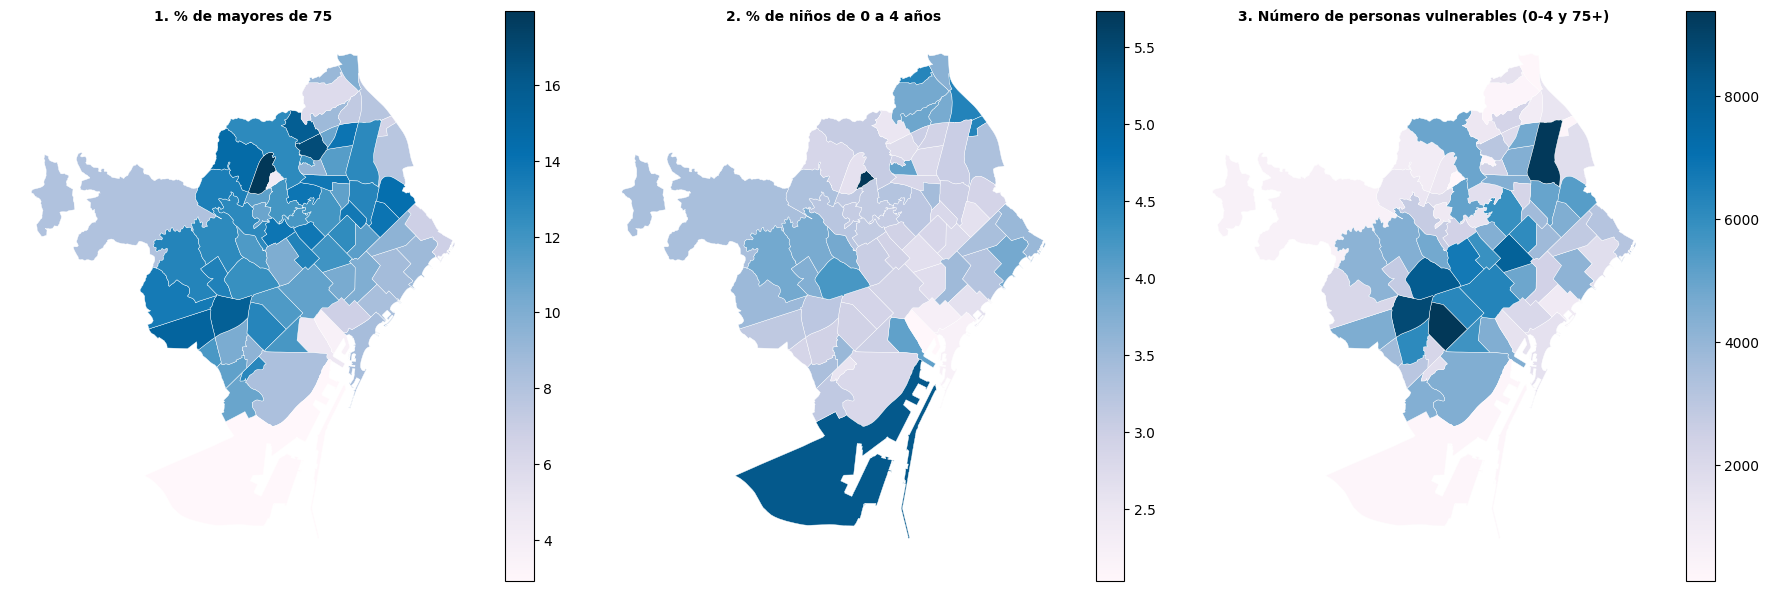

In [83]:
barrios_mapa = gpd.read_file(PROCESSED + 'barrios_base.gpkg')
mapa = barrios_mapa.merge(tabla[['codi_barri'] + VARIABLES], on='codi_barri')

fig, ejes = plt.subplots(1, 3, figsize=(18, 6))
columnas_grafica = [
    ('pct_75_mas', '1. % de mayores de 75'),
    ('pct_0_4', '2. % de niños de 0 a 4 años'),
    ('pob_vulnerable', '3. Número de personas vulnerables (0-4 y 75+)')
]

for i, (columna, titulo) in enumerate(columnas_grafica):
    mapa.plot(column=columna, cmap='PuBu', legend=True, ax=ejes[i], edgecolor='white', linewidth=0.3)
    ejes[i].set_title(titulo, fontsize=10, fontweight='bold')
    ejes[i].axis('off')

plt.tight_layout()
plt.show()

**Qué mirar:**

- **Mapa 1 (% de mayores de 75):** los porcentajes más altos se concentran en el norte y el noroeste (la Vall d'Hebron, la Guineueta y Canyelles), y los más bajos, en la Marina del Prat Vermell y los barrios de montaña.
- **Mapa 2 (% de niños de 0 a 4 años):** la Marina del Prat Vermell destaca mucho por su tamaño, pero tiene solo 167 niños. La Clota, que tiene el porcentaje más alto, apenas se ve porque es muy pequeña. En un mapa, los barrios grandes en superficie llaman más la atención que los que tienen más gente.
- **Mapa 3 (número de personas):** las personas vulnerables se concentran en Sant Andreu y en la Nova Esquerra de l'Eixample. Este mapa no se parece al del porcentaje, y por eso conviene mirar las dos medidas.

## 6. Guardamos el resultado

Guardamos `codi_barri` + las variables de población, con una fila por barrio.

In [84]:
salida = tabla[['codi_barri'] + VARIABLES].round(3)
salida.to_csv(PROCESSED + 'poblacion_por_barrio.csv', index=False, encoding='utf-8-sig')

print('Guardado:', salida.shape)
display(salida.head(3))

Guardado: (73, 10)


,codi_barri,pob_total,pob_0_4,pob_75_mas,pob_vulnerable,pct_0_4,pct_75_mas,pct_vulnerable,densidad_hab_km2,densidad_vulnerable_km2
0,1,50825,2054,2365,4419,4.041,4.653,8.695,46192.530,4016.228
1,2,27295,555,983,1538,2.033,3.601,5.635,33466.409,1885.742
2,3,14650,325,1248,1573,2.218,8.519,10.737,12421.760,1333.749
